In [35]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [36]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [46]:
canny = cv2.Canny(image_gray, 50, 150)

In [51]:
lines = cv2.HoughLinesP(canny, 1, np.pi/180, threshold=100, minLineLength=80, maxLineGap=3)

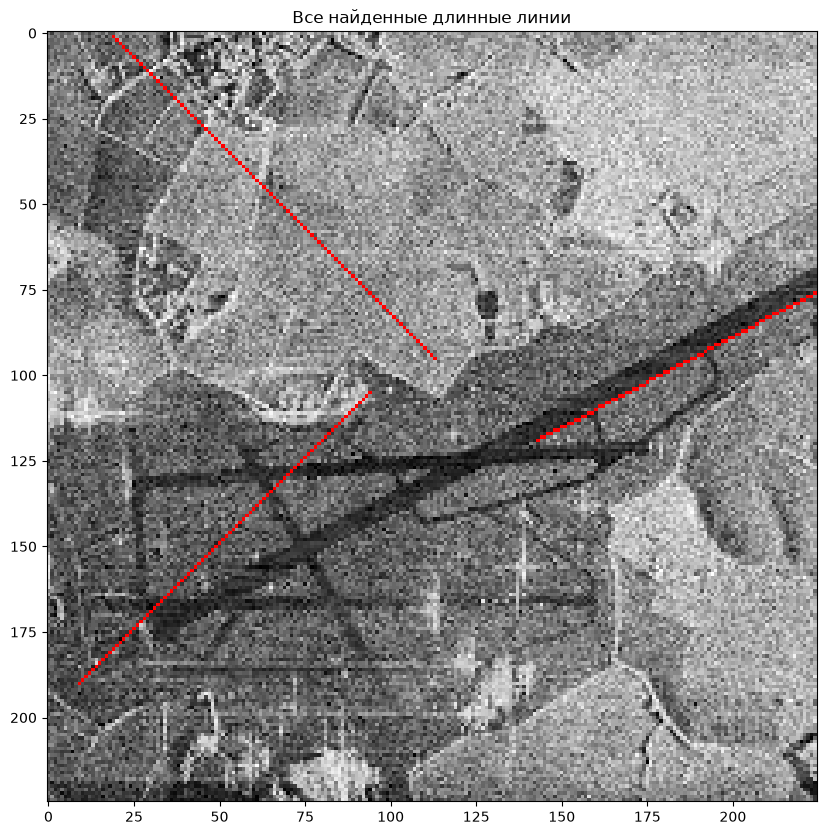

In [53]:
image_with_lines = image.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.ravel()
        length = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        if length > 50:
            cv2.line(image_with_lines, (x1, y1), (x2, y2), (0, 0, 255), 1)
    plt.figure(figsize=(10, 10))
    plt.imshow(cv2.cvtColor(image_with_lines, cv2.COLOR_BGR2RGB))
    plt.title('Все найденные длинные линии')
    plt.show()

In [54]:
#Вывелись лишнии линии, но самый длинный настоящий участок оказался вдоль дороги

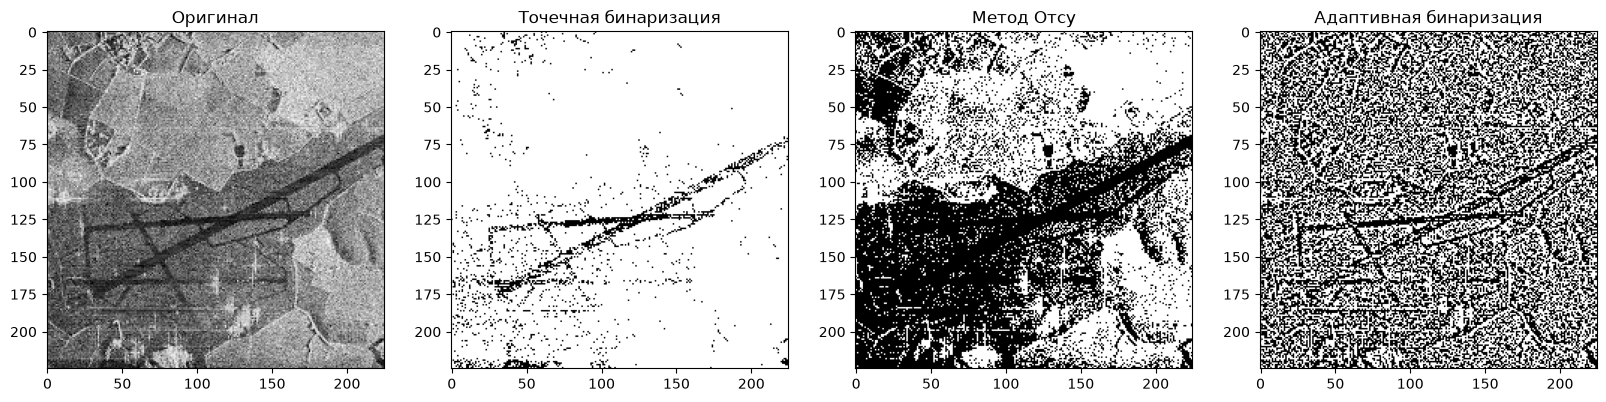

In [55]:
import copy
bin_img = copy.deepcopy(image_gray)
T_point = 50
bin_img[image_gray < T_point] = 0
bin_img[image_gray >= T_point] = 255
_, otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал')
plt.subplot(1, 4, 2), plt.imshow(bin_img, cmap='gray'), plt.title('Точечная бинаризация')
plt.subplot(1, 4, 3), plt.imshow(otsu, cmap='gray'), plt.title('Метод Отсу')
plt.subplot(1, 4, 4), plt.imshow(adaptive, cmap='gray'), plt.title('Адаптивная бинаризация')
plt.show()

In [56]:
#Лучше всего дорожный участок выделился при точечной бинаризации, в остальных методах на данной картинке оказаалось слишком много шума